# 1- This code is for the simulation of Acetyl-CoA, Malonyl-CoA,  FA and TAG model for the two regimes: degradation and synthesis of TAG in the case of Mass action Kinectic.

The code serve to understand the behavior of the model under different scenarios:
* Without any feedback 
* With feedback inhibition 
* Only the degradation of TAG
* Only the synthesis of TAG

We are interested to see how the dynamic of the internal metabolites influence the behavior of the system. We will further like to see how in which conditions the system can switch from the synthesis to degradation and vice versa.

<div>
<img src="Acetyl_CoA_vs_TAG.png" width="500"/>
</div>

We consider that the concentration of acetyl-CoA in the cell determine the energy state of the cell [1]. A low concentration indicate a fasting state whereas a high concentration indicate the a fed state. In case of fasting, TAG must be mobilized and breakdown to supply acetyl-CoA pool (red arrows path); whereas in the case of fed state, the surplus of acetyl-CoA must be converted to TAG (black arrows). The mechanism behind such regulation is not well undertood, mainly what are the parameter that trigger the system to run in a particular regime. We use a theoretical approach not based on mechanistic model  but rather to the abstractions of the system, where the reaction rates are choosen as simple as possible. Based on the conclusions resulting from the choice of kinetics, we further investigateb either by releasing assumptions or add more assumptions. This designing approach has the main objective to build a system that work in two regimes based on the concentration of Acetyl-CoA in the cell. 

## 1-  Desigining of the system 
We define the rates and the  differential equations that govern the dynamic of the system. For this we need the python module **Rate_laws**


In [1]:

#Library to be used 

import numpy as np
import scipy.integrate as sp
import matplotlib.pyplot as plt
from Rate_laws import *
from assimulo.solvers import CVode
from assimulo.problem import Explicit_Problem
from mpl_toolkits.mplot3d import Axes3D

In [2]:
#Compounds are metabolites in the system (variable of the system)
compounds = ["Acetyl_CoA", "Malonyl_CoA", "Fatty_Acyl", "TAG"]

n_compounds = len(compounds)

# Build of the rate of each reactions in the system

def get_rates(y, par):
    Acetyl_CoA, Malonyl_CoA, Fatty_Acyl, TAG = y
    par =par
    return {
        "v_in_1":
        constant_influx(par["a1"]),
        "v_in_2":
        constant_influx(par["a2"]),
        "v_in_3":
        constant_influx(par["a3"]),
        "r1":
        mass_action_with_inhib(par["k1"], Acetyl_CoA, Fatty_Acyl, par["Ki1"], par["n1"], par["c1"]),
        "r2":
        mass_action_simple(par["k2"], Acetyl_CoA, Malonyl_CoA),
        "r3":
        mass_action_simple(par["k3"], Fatty_Acyl),
        "r4":
        mass_action_simple(par["k4"], TAG),
        "r5":
         mass_action_with_inhib(par["k5"], Fatty_Acyl, Malonyl_CoA, par["Ki5"], par["n5"], par["c5"]),
        "v_out1":
        mass_action_simple(par["alpha1"], Acetyl_CoA),
        "v_out2":
        mass_action_simple(par["alpha2"], Fatty_Acyl),
        "v_out3":
        mass_action_simple(par["alpha3"], TAG),
    }


In [3]:
# Differential equations that  describe the dynamic of the system

def model(time, y, par):
    rates = get_rates(y=y, par=par)
    d_Acetyl_CoA_dt = (rates["v_in_1"] - rates["r1"] + rates["r5"] -
                       rates["v_out1"])
    d_Malony_CoA = rates["r1"] - rates["r2"]

    d_Fatty_Acyl = (rates["v_in_2"] + rates["r2"] - rates["r3"] + rates["r4"] -
                    rates["r5"] - rates["v_out2"])

    d_TAG_dt = rates["v_in_3"] + rates["r3"] - rates["r4"] - rates["v_out3"]

    return np.array([d_Acetyl_CoA_dt, d_Malony_CoA, d_Fatty_Acyl, d_TAG_dt])

To solve the system, we just need to provide the initial condition **y0** which is a np.array with the dimension of the number of metabolite  and the parameters **par** which is a dictionnary

In [4]:
# Function that simulate the steady state of the system
# It takes mainly three arguments in the following order:
# model: The differential equations that govern the dynamic of the system
# y0: The initial condition
# par: the parameter of the system 
# It uses scipy.integrate.ode (sp.ode) from the python  library scipy.
# The integration step (dt) can be adjusted 
# The tolerance (error) can also be adjusted
# The maximum number of steps for the integrator can be changed. 

def simulate_steady_state(model, y0, par, dt=1e-3, error=1e-7, max_steps=1e12):
    r = sp.ode(model)
    r.set_integrator("lsoda", method="bdf")
    r.set_f_params(par)
    r.set_initial_value(y0, 0.0)

    y1 = y0.copy()
    nsteps = 0
    while r.successful and nsteps < max_steps:
        y2 = r.integrate(r.t + dt)
        if np.linalg.norm(y1 - y2, ord=2) < error:
            return y2
        else:
            y1 = y2
        nsteps += 1
    raise ValueError("Maximal simulation steps exceeded")

## 2- Mass action Kinetics

### 2-1 All the reactions follow the simple mass actions kinetic

* We assume that there is a constant supplies of acetyl-CoA, Fatty acids and TAG. 
* We futher assume that the  above mentioned metabolites are suggested to proportional outflux
* We suppose that there is no inhibition in the system ($c_0$ , $c_5 = 0$). To consider inhibition, the two parameters must be simply set to 1.

The generale rate laws of the different reactions in the system are given by
$V_{in1} = a_1$,
$V_{in2} = a_2$,
$V_{in3} = a_3$,
$V_{out1} = \alpha_1\cdot S_1$,
$V_{out2} = \alpha_2\cdot S_2$,
$V_{out3} = \alpha_3\cdot S_3$,
$r_1 = k_1 S_1\cdot \dfrac{1}{1+(c_1 \cdot S_3/K_{i1})^n}$,
$r_2 = k_2\cdot S_1\cdot S_2$,
$r_3 = k_3 \cdot S_3$,
$r_4 = K_4\cdot S_4$,
$r_5 = k_5 \cdot S_3\cdot \dfrac{1}{1+(c_5\cdot S_2/K_{i1})^n}$


We first consider that we can have external source of fatty acids other than de novo synthesis and TAG hydrolysis ($a_2 \neq 0$). We futher consider that fatty acids can be used for external processes ($\alpha_2 \neq 0$).


In [5]:
# c1 and C5 are set to 0 (there is no inhibition in the system)

par = {
    "k1": 1.0,
    "k2": 1.0,
    "k3": 1.0,
    "k4": 1.0,
    "k5": 1.0,
    "k6": 1.0,
    "a1": 1.0,
    "a2": 0.0,
    "a3": 1.0,
    "alpha1": 1.0,
    "alpha2": 0.0,
    "alpha3": 1.0,
    "Ki1": 1.0,
    "Ki5": 1.0,
    "n1": 1.0,
    "n5":1.0,
    "c1":0.0,
    "c5":0.0,
    "y0":0.0
}


In [6]:
#intial condition 
y0= np.zeros(n_compounds)
y0[0] = par["y0"]

time = np.linspace(0, 10, 100)

#Solve the system 
y = sp.odeint(func=model, y0=y0, t=time, args=(par, ), tfirst=True)

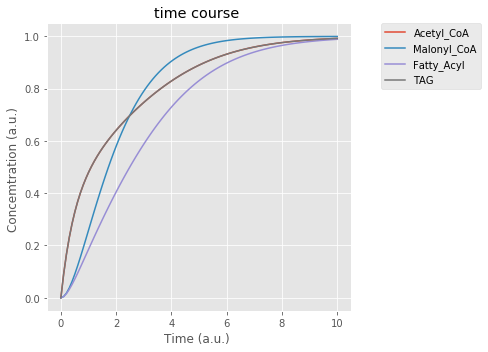

In [7]:
# Plot of the time course 

plt.style.use('ggplot')
fig, ax = plt.subplots(figsize=(7,5))
ax.plot(time, y)
plt.xlabel("Time (a.u.) ")
plt.ylabel("Concemtration (a.u.) ")
plt.title("time course ")
ax.legend(compounds,
          loc="upper left",
          bbox_to_anchor=(1.1, 1),
          borderaxespad=0)
plt.tight_layout()
#plt.savefig("Concentrations.png", bbox_inches='tight')
plt.show()

#### Remark 
We about set up  we can see that all the compounds have the same concentration at the equilibruim. We would like know to vary the influx of either Acetyl-CoA or TAG and see whether this result to the synthesis of TAG in the first case and the build up of acetyl-CoA in the second case.


In [8]:
#Vary the influx of Acetyl-CoA and  compute the  corresponding steady state and speeding for k1 =, k2 =, k3 =

par1 = par.copy()
par1["a3"] = 0.0
par1["alpha1"] = 0.0
par1["k1"] = 5.0
par1["k2"] = 5.0
par1["k3"] = 5.0

Var_a1 = [i for i in np.linspace(0, 5, 100)]
Steady_state_concentration1 = []
for i in Var_a1:
    par1.update({"a1": i})
    Steady_state_concentration1.append(
        simulate_steady_state(model, y0, par1, dt=100))

A = Var_a1
B = np.array(Steady_state_concentration1)

#Vary the influx of TAG and compute the  corresponding steady state

par2 = par.copy()

par2["a1"] = 0.0
par2["alpha3"] = 0.0
par2["k4"] = 5.0
par2["k5"] = 5.0


Var_a3 = [i for i in np.linspace(0, 5, 100)]
Steady_state_concentration2 = []
for i in Var_a3:
    par2.update({"a3": i})
    Steady_state_concentration2.append(
        simulate_steady_state(model, y0, par2, dt=100))

C = Var_a3
D = np.array(Steady_state_concentration2)

In [9]:
#Considering inhibition
par3 = par.copy()
par3["c1"] = 1.0
par3["c5"] =1.0


par3
par31 = par3.copy()
par31["a3"] = 0.0
par31["alpha1"] = 0.0
par31["k1"] = 5.0
par31["k2"] = 5.0
par31["k3"] = 5.0

Var_a31 = [i for i in np.linspace(0, 5, 100)]
Steady_state_concentration3 = []
for i in Var_a31:
    par31.update({"a1": i})
    Steady_state_concentration3.append(simulate_steady_state(model, y0, par31, dt=100))

E = Var_a31
F = np.array(Steady_state_concentration3)


#Vary the influx of TAG and compute the  corresponding steady state

par32 =par3.copy()
par32["a1"] = 0.0
par32["alpha3"] = 0.0
par32["k4"] = 5.0
par32["k5"] = 5.0
Var_a33 = [i for i in np.linspace(0, 5, 100)]
Steady_state_concentration4 = []
for i in Var_a33:
    par32.update({"a3": i})
    Steady_state_concentration4.append(simulate_steady_state(model, y0, par32, dt=100))

G = Var_a33
H = np.array(Steady_state_concentration4)
par31

{'k1': 5.0,
 'k2': 5.0,
 'k3': 5.0,
 'k4': 1.0,
 'k5': 1.0,
 'k6': 1.0,
 'a1': 5.0,
 'a2': 0.0,
 'a3': 0.0,
 'alpha1': 0.0,
 'alpha2': 0.0,
 'alpha3': 1.0,
 'Ki1': 1.0,
 'Ki5': 1.0,
 'n1': 1.0,
 'n5': 1.0,
 'c1': 1.0,
 'c5': 1.0,
 'y0': 0.0}

In [10]:
y2 = sp.odeint(func=model, y0=y0, t=time, args=(par32, ), tfirst=True)

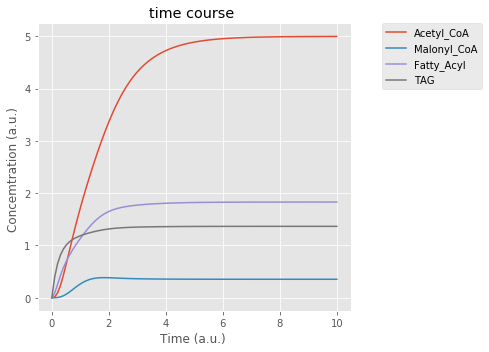

In [11]:
plt.style.use('ggplot')
fig, ax = plt.subplots(figsize=(7,5))
ax.plot(time, y2)
plt.xlabel("Time (a.u.) ")
plt.ylabel("Concemtration (a.u.) ")
plt.title("time course ")
ax.legend(compounds,
          loc="upper left",
          bbox_to_anchor=(1.1, 1),
          borderaxespad=0)
plt.tight_layout()
#plt.savefig("Concentrations.png", bbox_inches='tight')
plt.show()

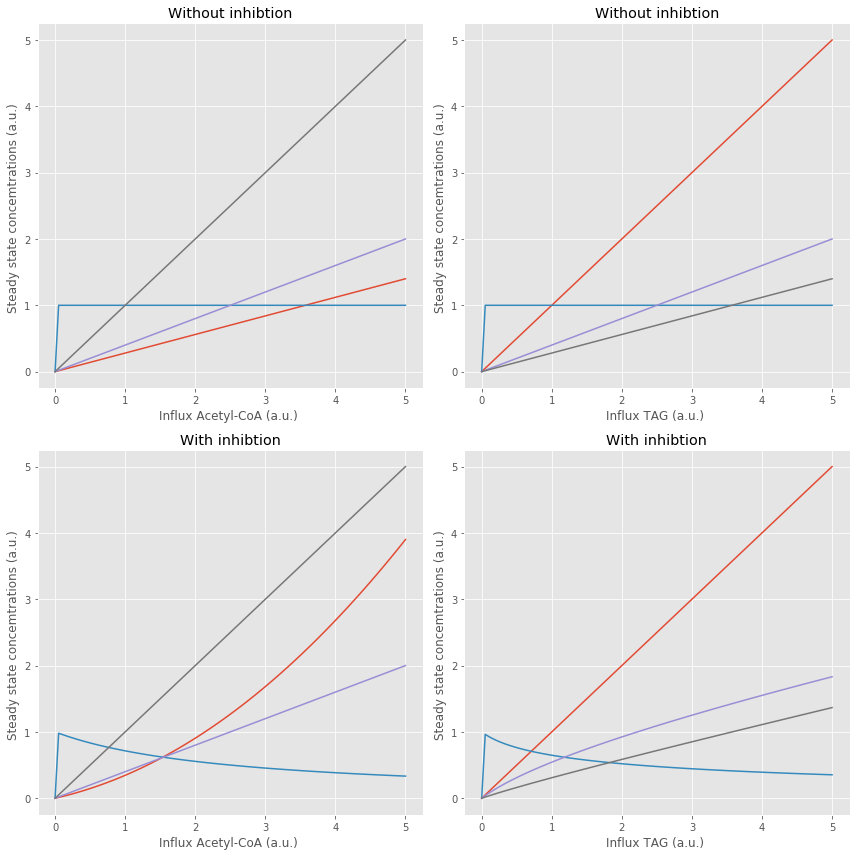

In [12]:
#Plot the steady state concentration as function of the influxes 

plt.style.use("ggplot")
fig, ax = plt.subplots(2,2, figsize=(12,12))
ax[0,0].plot(A, B)
ax[0,1].plot(C, D)
ax[0,0].set_xlabel("Influx Acetyl-CoA (a.u.) ")
ax[0,0].set_ylabel("Steady state concemtrations (a.u.) ")
ax[0,1].set_xlabel("Influx TAG (a.u.) ")
ax[0,1].set_ylabel("Steady state concemtrations (a.u.) ")
ax[0,0].set_title("Without inhibtion")
ax[0,1].set_title("Without inhibtion")
ax[1,0].plot(E, F)
ax[1,1].plot(G, H)
ax[1,0].set_xlabel("Influx Acetyl-CoA (a.u.) ")
ax[1,0].set_ylabel("Steady state concemtrations (a.u.) ")
ax[1,1].set_xlabel("Influx TAG (a.u.) ")
ax[1,1].set_ylabel("Steady state concemtrations (a.u.) ")
ax[1,0].set_title("With inhibtion")
ax[1,1].set_title("With inhibtion")

fig.subplots_adjust(hspace=0.3)
#plt.legend(compounds, loc="upper left", bbox_to_anchor=(1.1, 1), borderaxespad=0)
fig.tight_layout()
fig.savefig('fig1.png', dpi=300)
#plt.savefig("Concentrations_1.png", bbox_inches="tight")
plt.show()

The plot only show how we cannot achieve the objective by controling at least seperately the two considered influxes. But we have some information about what influxes are necessary for the system to achieve  a certain state.

We will know consider the case  where we do not have external source of fatty acid.

In [13]:
par

{'k1': 1.0,
 'k2': 1.0,
 'k3': 1.0,
 'k4': 1.0,
 'k5': 1.0,
 'k6': 1.0,
 'a1': 1.0,
 'a2': 0.0,
 'a3': 1.0,
 'alpha1': 1.0,
 'alpha2': 0.0,
 'alpha3': 1.0,
 'Ki1': 1.0,
 'Ki5': 1.0,
 'n1': 1.0,
 'n5': 1.0,
 'c1': 0.0,
 'c5': 0.0,
 'y0': 0.0}

In [14]:
#Update the parameters by changing the values of a2 and alpha2
# par["c1"] = 1.0
# par["c5"] =1.0
#new_par = par.copy()

In [15]:
y2 = sp.odeint(func=model, y0=y0, t=time, args=(par, ), tfirst=True)

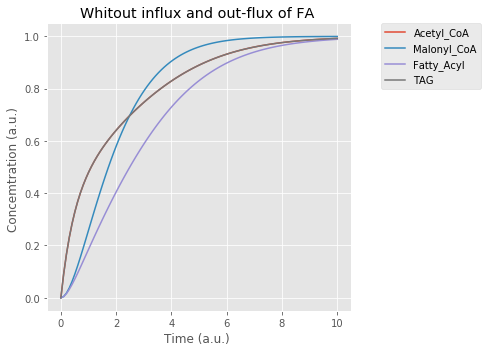

In [16]:
# Plot of the time course 

plt.style.use('ggplot')
fig, ax = plt.subplots(figsize=(7,5))
ax.plot(time, y2)
plt.xlabel("Time (a.u.) ")
plt.ylabel("Concemtration (a.u.) ")
plt.title("Whitout influx and out-flux of FA ")
ax.legend(compounds,
          loc="upper left",
          bbox_to_anchor=(1.1, 1),
          borderaxespad=0)
plt.tight_layout()
#plt.savefig("Concentrations.png", bbox_inches='tight')
plt.show()

In [17]:
#Vary the influx of Acetyl-CoA and  compute the  corresponding steady state

par4 =par.copy()


Var_a14 = [i for i in np.linspace(0, 5, 100)]
Steady_state_concentration = []
for i in Var_a14:
    par4.update({"a1": i})
    Steady_state_concentration.append(simulate_steady_state(model, y0, par4, dt=100))

H = Var_a14
I = np.array(Steady_state_concentration)


#Vary the influx of TAG and compute the  corresponding steady state

par5 =par.copy()

Var_a34 = [i for i in np.linspace(0, 5, 100)]
Steady_state_concentration = []
for i in Var_a34:
    par5.update({"a3": i})
    Steady_state_concentration.append(simulate_steady_state(model, y0, par5, dt=100))

J = Var_a3
K = np.array(Steady_state_concentration)


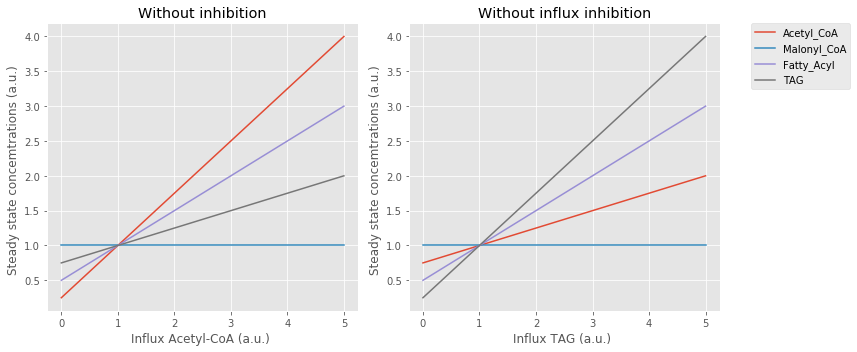

In [18]:
#Plot the steady state concentration as function of the influxes 

plt.style.use("ggplot")
fig, ax = plt.subplots(1,2, figsize=(12,5))
ax[0].plot(H, I)
ax[1].plot(J, K)
ax[0].set_xlabel("Influx Acetyl-CoA (a.u.) ")
ax[0].set_ylabel("Steady state concemtrations (a.u.) ")
ax[1].set_xlabel("Influx TAG (a.u.) ")
ax[1].set_ylabel("Steady state concemtrations (a.u.) ")
ax[0].set_title("Without inhibition")
ax[1].set_title("Without influx inhibition")

#plt.title("Steady state concentration vs Influx TAG ")


plt.legend(compounds, loc="upper left", bbox_to_anchor=(1.1, 1), borderaxespad=0)
plt.tight_layout()
#plt.savefig("Concentrations_1.png", bbox_inches="tight")
plt.show()

#### Remark
By playing on the targeted metabolites, it is hard to achieve the synthesis or the breakdown of TAG without 

### 1-2 The set up of the model without a distinction of the regimes.

* We assume that there is a constant supplies of acetyl-CoA, Fatty acids and TAG. 
* We futher assume that the  above mentioned metabolites are suggested to proportional outflux
* We suppose the general system where inhibition is considered ($c_1$ , $c_5 = 1$). To get rid of inhibition, the two parameters must be simply set to 0.






In [19]:
# par = {
#     "k1": 1.0,
#     "k2": 1.0,
#     "k3": 1.0,
#     "k4": 1.0,
#     "k5": 1.0,
#     "k6": 1.0,
#     "a1": 1.0,
#     "a2": 1.0,
#     "a3": 0.0,
#     "alpha1": 1.0,
#     "alpha2": 1.0,
#     "alpha3": 1.0,
#     "Ki1": 1.0,
#     "Ki5": 1.0,
#     "n1": 1.0,
#     "n5":1.0,
#     "c1":0.0,
#     "c5":0.0,
#     "y0":0.0
# }

In [20]:
compounds = ["Acetyl_CoA", "Malonyl_CoA", "Fatty_Acyl", "TAG"]

n_compounds = len(compounds)

def get_rates(y, par):
    Acetyl_CoA, Malonyl_CoA, Fatty_Acyl, TAG = y
    return {
        "v_in_1":
        constant_influx(par["a1"]),
        "v_in_2":
        constant_influx(par["a2"]),
        "v_in_3":
        constant_influx(par["a3"]),
        "r1":
        mass_action_with_inhib(par["k1"], Acetyl_CoA, Fatty_Acyl, par["Ki1"], par["n1"], par["c1"]),
        "r2":
        mass_action_simple(par["k2"], Acetyl_CoA, Malonyl_CoA),
        "r3":
        mass_action_simple(par["k3"], Fatty_Acyl),
        "r4":
        mass_action_simple(par["k4"], TAG),
        "r5":
         mass_action_with_inhib(par["k5"], Fatty_Acyl, Malonyl_CoA, par["Ki5"], par["n5"], par["c5"]),
        "v_out1":
        mass_action_simple(par["alpha1"], Acetyl_CoA),
        "v_out2":
        mass_action_simple(par["alpha2"], Fatty_Acyl),
        "v_out3":
        mass_action_simple(par["alpha3"], TAG),
    }


In [21]:
def model(time, y, par):
    rates = get_rates(y=y, par=par)
    d_Acetyl_CoA_dt = (rates["v_in_1"] - rates["r1"] + rates["r5"] -
                       rates["v_out1"])
    d_Malony_CoA = rates["r1"] - rates["r2"]

    d_Fatty_Acyl = (rates["v_in_2"] + rates["r2"] - rates["r3"] + rates["r4"] -
                    rates["r5"] - rates["v_out2"])

    d_TAG_dt = rates["v_in_3"] + rates["r3"] - rates["r4"] - rates["v_out3"]

    return np.array([d_Acetyl_CoA_dt, d_Malony_CoA, d_Fatty_Acyl, d_TAG_dt])


In [22]:
y0= np.zeros(n_compounds)
y0[0] = par["y0"]

time = np.linspace(0, 10, 100)
y = sp.odeint(func=model, y0=y0, t=time, args=(par, ), tfirst=True)

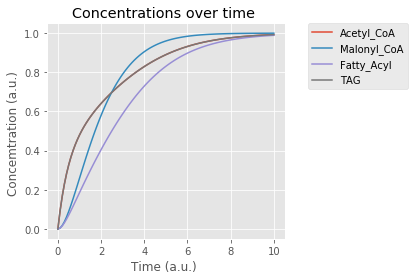

In [23]:
plt.style.use('ggplot')
fig, ax = plt.subplots()
ax.plot(time, y)
plt.xlabel("Time (a.u.) ")
plt.ylabel("Concemtration (a.u.) ")
plt.title("Concentrations over time ")
ax.legend(compounds,
          loc="upper left",
          bbox_to_anchor=(1.1, 1),
          borderaxespad=0)
plt.tight_layout()
plt.savefig("Concentrations.png", bbox_inches='tight')
plt.show()

In [24]:

#steady =  list(simulate_steady_state(model,y0, par, dt=100))

In [25]:
par1 =par.copy()
par1["a3"] =3 #set the influx of TAG to 0

Var_a1 = [i for i in np.linspace(0, 5, 100)]
Steady_state_concentration = []
for i in Var_a1:
    par1.update({"a1": i})
    Steady_state_concentration.append(simulate_steady_state(model, y0, par1, dt=100))

A = Var_a1
B = np.array(Steady_state_concentration)
#B[:,0]


In [26]:
# plt.style.use("ggplot")
# fig, ax = plt.subplots()
# ax.plot(A, B)
# plt.xlabel("Influx Acetyl-CoA (a.u.) ")
# plt.ylabel("Steady state concemtrations (a.u.) ")
# plt.title("Steady state concentration vs Influx Acetyl-CoA ")
# ax.legend(compounds, loc="upper left", bbox_to_anchor=(1.1, 1), borderaxespad=0)
# plt.tight_layout()
# #plt.savefig("Concentrations_1.png", bbox_inches="tight")
# plt.show()

In [27]:
par2 =par.copy()
par2["a1"] = 0
Var_a3 = [i for i in np.linspace(0, 5, 100)]
Steady_state_concentration = []
for i in Var_a3:
    par2.update({"a3": i})
    Steady_state_concentration.append(simulate_steady_state(model, y0, par2, dt=100))

C = Var_a3
D = np.array(Steady_state_concentration)

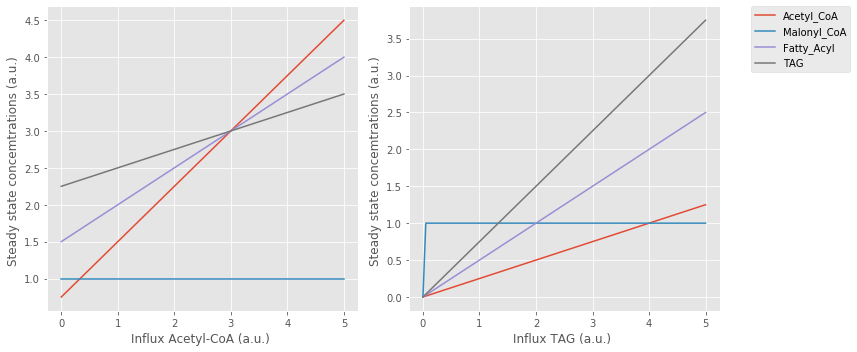

In [28]:
plt.style.use("ggplot")
fig, ax = plt.subplots(1,2, figsize=(12,5))
ax[0].plot(A, B)
ax[1].plot(C, D)
ax[0].set_xlabel("Influx Acetyl-CoA (a.u.) ")
ax[0].set_ylabel("Steady state concemtrations (a.u.) ")
ax[1].set_xlabel("Influx TAG (a.u.) ")
ax[1].set_ylabel("Steady state concemtrations (a.u.) ")
#plt.title("Steady state concentration vs Influx TAG ")


plt.legend(compounds, loc="upper left", bbox_to_anchor=(1.1, 1), borderaxespad=0)
plt.tight_layout()
#fig.savefig('fig1.png')
#plt.savefig("Concentrations_1.png", bbox_inches="tight")
plt.show()

### Remark

We such a system, we can clearly see that a high influx of Acetyl-CoA does not result to the synthesis of TAG but rather to the overload of the Acetyl-CoA pool, Simirlarly, a high influx of TAG does results to a overload of TAG pool instead of their breakdown to Acetyl-CoA. This suggest the use of a different strategy.

### 1-2  Fatty acids pools  are not subjected to  external influences ($a_2$= $\alpha_2 = 0$).

In [29]:
# par1 =par.copy()

# Var_a1 = [i for i in np.linspace(0, 5, 100)]
# Steady_state_concentration = []
# for i in Var_a1:
#     par1.update({"a1": i})
#     Steady_state_concentration.append(simulate_steady_state(model, y0, par1, dt=100))

# A = Var_a1
# B = np.array(Steady_state_concentration)


In [30]:
# par2 =par.copy()

# Var_a3 = [i for i in np.linspace(0, 5, 100)]
# Steady_state_concentration = []
# for i in Var_a3:
#     par2.update({"a3": i})
#     Steady_state_concentration.append(simulate_steady_state(model, y0, par2, dt=100))

# C = Var_a3
# D = np.array(Steady_state_concentration)
# par2

In [31]:
# plt.style.use("ggplot")
# fig, ax = plt.subplots(1,2, figsize=(12,5))
# ax[0].plot(A, B)
# ax[1].plot(C, D)
# ax[0].set_xlabel("Influx Acetyl-CoA (a.u.) ")
# ax[0].set_ylabel("Steady state concemtrations (a.u.) ")
# ax[1].set_xlabel("Influx TAG (a.u.) ")
# ax[1].set_ylabel("Steady state concemtrations (a.u.) ")
# #plt.title("Steady state concentration vs Influx TAG ")


# plt.legend(compounds, loc="upper left", bbox_to_anchor=(1.1, 1), borderaxespad=0)
# plt.tight_layout()
# #plt.savefig("Concentrations_1.png", bbox_inches="tight")
# plt.show()

### Remark 

As previously, with a high influx of Acetyl-CoA, we still cannot produce TAG and vice versa. We need to 

In [32]:


# # Useful convention: use lowercase variables for the input
# # and uppercase variables for the meshgrid

# # You also will want to have a 2-D array, such that
# # matplotlib knows which data points belong to which
# # meshgrid point

# x = np.linspace(0, 5, 10)
# y = np.linspace(0, 5, 10)
# z = []
# for i in x:
#     temp = []
#     for j in y:
#         par["a1"] = i
#         par["a3"] = j
#         temp.append(simulate_steady_state(model, y0, par, dt=100))
#     z.append(np.array(temp))
# X, Y = np.meshgrid(x, y)
# Z = np.array(z)

# # Watch out that these shapes always match, since Z is over five variables
# # of course you can only take one of them at a time
# print(X.shape, Y.shape, Z.shape)

# # (10, 10) (10, 10) (10, 10, 5)

# # You probably want to have them in separate plots
# fig, axs = plt.subplots(2, 3, figsize=(12, 10), subplot_kw={"projection": "3d"})
# for (i, cpd), ax in zip(enumerate(compounds), axs.ravel()):
#     ax.plot_surface(X, Y, Z[:, :, i])
#     ax.set_title(cpd)
# fig.tight_layout()
# plt.show()

## References
<a id="1">[1]</a> 
Lei Shi and Benjamin P Tu. Acetyl-coa and the regulation of metabolism: mechanisms and consequences. Current opinion in cell biology, 33:125–131, 2015